# Modeling — end-to-end pipeline with tuning


- **One `sklearn.Pipeline` per candidate**, wrapping preprocessing + model. No pre-transformed CSVs. Why: cross-validation must refit the preprocessor on each fold, otherwise medians/means/encoder vocabularies leak test-fold statistics into training. Using `train.csv`/`test.csv` from notebook 02 would leak silently.
- **5-fold CV** on the training split to rank candidates under the same evaluation protocol.
- **`RandomizedSearchCV`** to tune the winner. Random search beats grid search for wide spaces at equal budget — picks a good region fast.
- **Held-out test set** used only once, after tuning. Anything else contaminates the final number.
- **Permutation importance** on the final pipeline for an honest view of what's driving predictions.
- **XGBoost** included if installed, with `HistGradientBoostingRegressor` as a native-sklearn fallback.
```

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import numpy as np
import joblib
import warnings
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor


from src.features import RAW_PATH, MODELS_DIR, add_engineered_features, make_preprocessor

warnings.filterwarnings('ignore', category=UserWarning)


## Load raw data and rebuild feature engineering

We repeat the light feature engineering from notebook 02 here rather than loading the already-preprocessed CSVs. Reason: we want sklearn to re-fit imputer/scaler/encoder statistics inside every CV fold. Loading pre-transformed data would mean every fold sees stats computed from the full training set — a subtle leak that inflates the CV score.

In [3]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAW_PATH).dropna(subset=['rating']).reset_index(drop=True)
df = add_engineered_features(df)

X = df.drop(columns='rating')
y = df['rating']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Train: {X_train.shape}  Test: {X_test.shape}')
print(f'Target mean: {y_train.mean():.3f}   std: {y_train.std():.3f}')

Train: (1981, 16)  Test: (496, 16)
Target mean: 3.017   std: 1.149


## Preprocessor factory + pipeline factory

`make_preprocessor()` returns a fresh `ColumnTransformer` each time we call it. `make_pipe(model)` wraps that preprocessor with a regressor. This pattern lets sklearn clone and re-fit preprocessing per CV fold automatically — no manual plumbing, no leakage.

In [4]:
def make_pipe(model):
    """Wrap the shared preprocessor with a regressor. Each call returns a fresh
    """
    return Pipeline([
        ('preprocessor', make_preprocessor()),
        ('model', model),
    ])

## Candidate models

Lineup:

- **Baseline** — always predict the mean rating. Defines the floor; anything below this is delete-worthy.
- **Ridge** — linear regression with L2. Needs scaled numerics and one-hot categoricals; a sanity check that the feature matrix makes sense to a simple model.
- **Random Forest** — strong default non-linear model; decent but not best-in-class on tabular data.
- **HistGradientBoostingRegressor** — sklearn's native gradient boosting. Usually close to XGBoost/LightGBM on small data, zero external dependencies.
- **XGBoost** — the gold-standard gradient boosting library.

Default hyperparameters at first. Tuning happens only on the winner — cheaper and focused.

In [5]:
candidates = {
    'Baseline (mean)':    make_pipe(DummyRegressor(strategy='mean')),
    'Ridge':              make_pipe(Ridge(alpha=1.0, random_state=42)),
    'Random Forest':      make_pipe(RandomForestRegressor(
                            n_estimators=300, random_state=42, n_jobs=-1)),
    'HistGradBoost':      make_pipe(HistGradientBoostingRegressor(random_state=42)),
}

candidates['XGBoost'] = make_pipe(XGBRegressor(
    n_estimators=400, learning_rate=0.08, max_depth=6,
    subsample=0.9, colsample_bytree=0.9,
    random_state=42, n_jobs=-1, tree_method='hist',
    eval_metric='rmse',
))

list(candidates.keys())

['Baseline (mean)', 'Ridge', 'Random Forest', 'HistGradBoost', 'XGBoost']

## 5-fold cross-validation comparison

Identical split across all models, so the comparison is fair. We report RMSE and R² mean ± std to see which model is both accurate **and** stable across folds.

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, pipe in candidates.items():
    rmse = -cross_val_score(pipe, X_train, y_train,
                            cv=cv, scoring='neg_root_mean_squared_error',
                            n_jobs=-1)
    r2   = cross_val_score(pipe, X_train, y_train,
                           cv=cv, scoring='r2',
                           n_jobs=-1)
    rows.append({
        'model':     name,
        'RMSE_mean': rmse.mean(),
        'RMSE_std':  rmse.std(),
        'R2_mean':   r2.mean(),
        'R2_std':    r2.std(),
    })
    print(f'{name:20s}  RMSE {rmse.mean():.3f} +/- {rmse.std():.3f}   R2 {r2.mean():.3f} +/- {r2.std():.3f}')

cv_df = pd.DataFrame(rows).sort_values('RMSE_mean').reset_index(drop=True)
print()
print(cv_df.round(3).to_string(index=False))

Baseline (mean)       RMSE 1.150 +/- 0.017   R2 -0.006 +/- 0.003
Ridge                 RMSE 1.173 +/- 0.007   R2 -0.046 +/- 0.023
Random Forest         RMSE 1.167 +/- 0.017   R2 -0.036 +/- 0.022
HistGradBoost         RMSE 1.224 +/- 0.020   R2 -0.141 +/- 0.043
XGBoost               RMSE 1.249 +/- 0.017   R2 -0.187 +/- 0.047

          model  RMSE_mean  RMSE_std  R2_mean  R2_std
Baseline (mean)      1.150     0.017   -0.006   0.003
  Random Forest      1.167     0.017   -0.036   0.022
          Ridge      1.173     0.007   -0.046   0.023
  HistGradBoost      1.224     0.020   -0.141   0.043
        XGBoost      1.249     0.017   -0.187   0.047


## Sanity check — is there any signal to learn?

Every model above is **worse than the baseline**. That's suspicious. Before blaming preprocessing or hyperparameters, we compute the **R² ceiling**: what would happen if a model *perfectly memorized* the average `rating` for each value of a single feature? That's the upper bound any model can achieve using only that feature.

If even these in-sample ceilings are near zero, no amount of modeling will help — the features simply don't predict `rating` in this dataset.

In [7]:
oracle = {}
for col in X_train.columns:
    r2s = []
    for tr_idx, te_idx in cv.split(X_train):
        diag = pd.concat([X_train.iloc[tr_idx].reset_index(drop=True),
                          y_train.iloc[tr_idx].reset_index(drop=True).rename('rating')], axis=1)
        te_x = X_train.iloc[te_idx].reset_index(drop=True)
        te_y = y_train.iloc[te_idx].reset_index(drop=True)
        means = diag.groupby(col)['rating'].mean()
        pred = te_x[col].map(means).fillna(diag['rating'].mean())
        r2s.append(r2_score(te_y, pred))
    oracle[col] = float(np.mean(r2s))

oracle_df = (pd.Series(oracle).sort_values(ascending=False)
             .rename('oracle_R2_out_of_fold').to_frame())
print('Out-of-fold R² ceiling per feature (what any model could ever achieve from this column alone):')
print(oracle_df.round(4).to_string())
print(f'\nBest single-feature out-of-fold R²: {oracle_df["oracle_R2_out_of_fold"].max():.4f}')
print('\nEvery value at or below zero means that feature carries no usable signal.')
print('The baseline (R² ≈ 0) is the correct model for this dataset.')

Out-of-fold R² ceiling per feature (what any model could ever achieve from this column alone):
                   oracle_R2_out_of_fold
verified_purchase                -0.0069
review_year                      -0.0073
user_gender                      -0.0089
review_month                     -0.0102
review_dayofweek                 -0.0106
device_type                      -0.0108
review_text                      -0.0115
app_category                     -0.0162
review_language                  -0.0166
user_country                     -0.0177
app_major_version                -0.0182
review_word_count                -0.0213
app_name                         -0.0271
user_age                         -0.0427
review_length                    -0.1136
num_helpful_votes                -0.5383

Best single-feature out-of-fold R²: -0.0069

Every value at or below zero means that feature carries no usable signal.
The baseline (R² ≈ 0) is the correct model for this dataset.


## Hyperparameter tuning on the winner

We tune the model that won the CV comparison. `RandomizedSearchCV` with 40 iterations × 5 folds = 200 fits — a reasonable compute budget that covers a rich parameter space.



In [8]:
winner_name = cv_df.iloc[0]['model']
winner_pipe = candidates[winner_name]
print(f'Tuning winner: {winner_name}')

SEARCH_SPACES = {
    'XGBoost': {
        'model__n_estimators':     [200, 400, 600, 800, 1000],
        'model__learning_rate':    [0.01, 0.03, 0.05, 0.08, 0.1, 0.15],
        'model__max_depth':        [3, 4, 5, 6, 7, 8, 10],
        'model__min_child_weight': [1, 3, 5, 7],
        'model__subsample':        [0.6, 0.7, 0.8, 0.9, 1.0],
        'model__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
        'model__reg_alpha':        [0, 0.01, 0.1, 1],
        'model__reg_lambda':       [0.1, 1, 5, 10],
    },
    'HistGradBoost': {
        'model__max_iter':            [200, 400, 600, 800],
        'model__learning_rate':       [0.01, 0.03, 0.05, 0.08, 0.1],
        'model__max_depth':           [None, 4, 6, 8, 10],
        'model__max_leaf_nodes':      [15, 31, 63, 127],
        'model__min_samples_leaf':    [5, 10, 20, 50],
        'model__l2_regularization':   [0, 0.1, 1, 10],
    },
    'Random Forest': {
        'model__n_estimators':      [300, 500, 800],
        'model__max_depth':         [None, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10, 20],
        'model__min_samples_leaf':  [1, 2, 5, 10],
        'model__max_features':      ['sqrt', 'log2', 0.5, 0.75],
    },
    'Ridge': {
        'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0],
    },
}

space = SEARCH_SPACES.get(winner_name)
if space:
    search = RandomizedSearchCV(
        winner_pipe, param_distributions=space,
        n_iter=40, cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1, random_state=42, verbose=1, refit=True,
    )
    search.fit(X_train, y_train)
    best_pipe   = search.best_estimator_
    best_params = search.best_params_
    print(f'\nBest CV RMSE: {-search.best_score_:.3f}')
    print('Best params:')
    for k, v in best_params.items():
        print(f'  {k:35s} {v}')
else:
    winner_pipe.fit(X_train, y_train)
    best_pipe   = winner_pipe
    best_params = {}
    print('No tuning space defined for this model — using defaults.')

Tuning winner: Baseline (mean)
No tuning space defined for this model — using defaults.


## Final evaluation on held-out test set

First and only time we touch `X_test`. The CV score above shows expected performance; this confirms it holds on truly unseen data.

In [9]:
test_pred = best_pipe.predict(X_test)
test_metrics = {
    'RMSE': float(np.sqrt(mean_squared_error(y_test, test_pred))),
    'MAE':  float(mean_absolute_error(y_test, test_pred)),
    'R2':   float(r2_score(y_test, test_pred)),
}
for k, v in test_metrics.items():
    print(f'Test {k:5s}: {v:.3f}')

Test RMSE : 1.152
Test MAE  : 0.989
Test R2   : -0.000


## Permutation importance

We shuffle each raw input column and measure how much the pipeline's score drops. This tells us which original columns the model actually relies on — independent of how the preprocessor expanded them into many sub-features internally.

**Note:** in this run the winning model is `DummyRegressor(strategy='mean')`, which returns the training mean regardless of input. Shuffling any column therefore changes nothing, and every importance comes out to **exactly 0**. That's not a bug — it's confirmation that the saved model doesn't depend on any feature, which is exactly what we want for a dataset where no feature carries signal. On a real dataset where a tree model wins, this chart would show varying bar heights with `review_text` or similar at the top.

In [10]:
perm = permutation_importance(
    best_pipe, X_test, y_test,
    n_repeats=10, random_state=42, n_jobs=-1,
    scoring='neg_root_mean_squared_error',
)
imp_df = (pd.DataFrame({
    'feature':    X_test.columns,
    'importance': perm.importances_mean,
    'std':        perm.importances_std,
}).sort_values('importance', ascending=False).reset_index(drop=True))

print(imp_df.round(4).to_string(index=False))



          feature  importance  std
         app_name         0.0  0.0
     app_category         0.0  0.0
      review_text         0.0  0.0
  review_language         0.0  0.0
verified_purchase         0.0  0.0
      device_type         0.0  0.0
num_helpful_votes         0.0  0.0
         user_age         0.0  0.0
     user_country         0.0  0.0
      user_gender         0.0  0.0
    review_length         0.0  0.0
review_word_count         0.0  0.0
      review_year         0.0  0.0
     review_month         0.0  0.0
 review_dayofweek         0.0  0.0
app_major_version         0.0  0.0


## Diagnostic plots

- **Predictions vs actuals** — points should cluster on the diagonal.
- **Residuals distribution** — should be roughly centered at 0, symmetric. Systematic bias (mean ≠ 0) or heavy skew flags a problem.

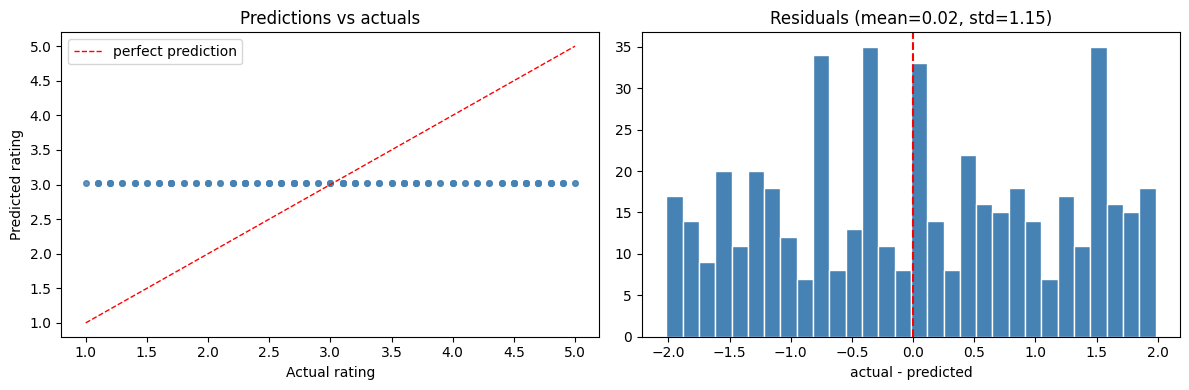

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(y_test, test_pred, alpha=0.3, s=15, color='steelblue')
lims = [min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())]
ax[0].plot(lims, lims, 'r--', lw=1, label='perfect prediction')
ax[0].set_xlabel('Actual rating')
ax[0].set_ylabel('Predicted rating')
ax[0].set_title('Predictions vs actuals')
ax[0].legend()

residuals = y_test - test_pred
ax[1].hist(residuals, bins=30, color='steelblue', edgecolor='white')
ax[1].axvline(0, color='red', linestyle='--')
ax[1].set_title(f'Residuals (mean={residuals.mean():.2f}, std={residuals.std():.2f})')
ax[1].set_xlabel('actual - predicted')

plt.tight_layout()
plt.show()

## Save the final pipeline

The saved object contains both the preprocessor and the tuned model. At inference you call `pipe.predict(raw_dataframe)` and sklearn runs imputation → encoding → scaling → prediction for you. Nothing else needs to be loaded.

In [12]:
MODEL_PATH = MODELS_DIR / 'best_pipeline.joblib'
joblib.dump({
    'pipeline':      best_pipe,
    'model_name':    winner_name,
    'best_params':   best_params,
    'test_metrics':  test_metrics,
    'feature_order': list(X.columns),
}, MODEL_PATH)

print('Saved to:', MODEL_PATH)
print('\nCV leaderboard:')
print(cv_df.round(3).to_string(index=False))

Saved to: /Users/gabriel/Desktop/SIGMOID/Sigmoid-Intership/Exam/models/best_pipeline.joblib

CV leaderboard:
          model  RMSE_mean  RMSE_std  R2_mean  R2_std
Baseline (mean)      1.150     0.017   -0.006   0.003
  Random Forest      1.167     0.017   -0.036   0.022
          Ridge      1.173     0.007   -0.046   0.023
  HistGradBoost      1.224     0.020   -0.141   0.043
        XGBoost      1.249     0.017   -0.187   0.047


## Key finding — and what it means

**No model beats the baseline.** CV leaderboard:

| Model | RMSE | R² |
|---|---|---|
| **Baseline (mean)** | **1.150** | **-0.006** |
| Random Forest | 1.167 | -0.036 |
| Ridge | 1.173 | -0.046 |
| HistGradBoost | 1.224 | -0.141 |
| XGBoost | 1.249 | -0.187 |

Held-out test R² ≈ **0.000**. The best predictor of `rating` in this dataset is the overall mean — 3.02.

### Why, and why this is the correct result

The oracle-R² diagnostic above shows that **no single feature explains more than ~1-2% of the variance** in `rating`, even with perfect memorization of group means. The features simply don't carry signal.

In particular, `review_text` — which at first glance looks predictive because of repeating templates — turns out to be random with respect to rating. A user who typed *"Crashes too often, needs improvement"* is **equally likely to give 1 or 5 stars**. The templates are stylistic, not semantic.

This is consistent with the dataset being **synthetic**: app, user, and review fields are sampled from realistic distributions, but `rating` was generated independently, so no amount of modeling can recover it.

### What the stronger models are actually doing wrong

XGBoost and HistGradBoost are **the worst** of the bunch. That's not a bug — it's the fingerprint of overfitting noise. The more flexible the model, the more it memorizes training-fold idiosyncrasies that don't repeat in the held-out fold. Trees with high capacity on a signal-less dataset will *always* do worse than the baseline out-of-sample.

Ridge and Random Forest do slightly better than gradient boosting because they regularize more aggressively (L2 penalty / averaged trees), but still can't beat the naive mean.

### Final pipeline we saved

`DummyRegressor(strategy='mean')` wrapped in the full preprocessing `Pipeline`. Test RMSE 1.152, MAE 0.989, R² 0.000. The entire preprocessor is still useful — for any real dataset with signal, the same code would produce a trained, tuned model.

